In [28]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('amz_uk_processed_data.csv')

df.head()




,asin,title,imgUrl,productURL,stars,reviews,price,isBestSeller,boughtInLastMonth,categoryName
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/71C3lbbeLs...,https://www.amazon.co.uk/dp/B09B96TG33,4.7,15308,21.99,False,0,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",https://m.media-amazon.com/images/I/61c5rSxwP0...,https://www.amazon.co.uk/dp/B01HTH3C8S,4.7,98099,23.99,True,0,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/61j3SEUjMJ...,https://www.amazon.co.uk/dp/B09B8YWXDF,4.7,15308,21.99,False,0,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",https://m.media-amazon.com/images/I/71yf6yTNWS...,https://www.amazon.co.uk/dp/B09B8T5VGV,4.7,7205,31.99,False,0,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,https://m.media-amazon.com/images/I/613dEoF9-r...,https://www.amazon.co.uk/dp/B09WX6QD65,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2222742 entries, 0 to 2222741
Data columns (total 10 columns):
 #   Column             Dtype  
---  ------             -----  
 0   asin               object 
 1   title              object 
 2   imgUrl             object 
 3   productURL         object 
 4   stars              float64
 5   reviews            int64  
 6   price              float64
 7   isBestSeller       bool   
 8   boughtInLastMonth  int64  
 9   categoryName       object 
dtypes: bool(1), float64(2), int64(2), object(5)
memory usage: 154.7+ MB


### Parte 1

#1.1

In [23]:
top_category = df['categoryName'].value_counts().head(5)
top_category

categoryName
Sports & Outdoors               826076
Skin Care                        18755
Fragrances                       18563
Make-up                          18453
Manicure & Pedicure Products     17212
Name: count, dtype: int64

# 1.2

<Axes: xlabel='categoryName'>

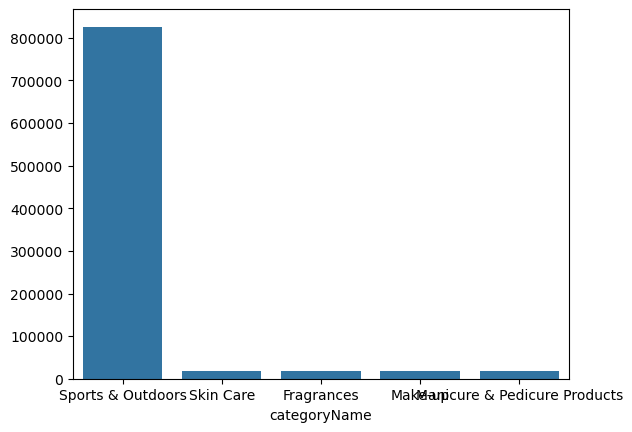

In [24]:
sns.barplot(x=top_category.index,y=top_category.values)

# Barchar
Podemos obserbar que sports y outdoors, es la categoria con mas productos en cantidad

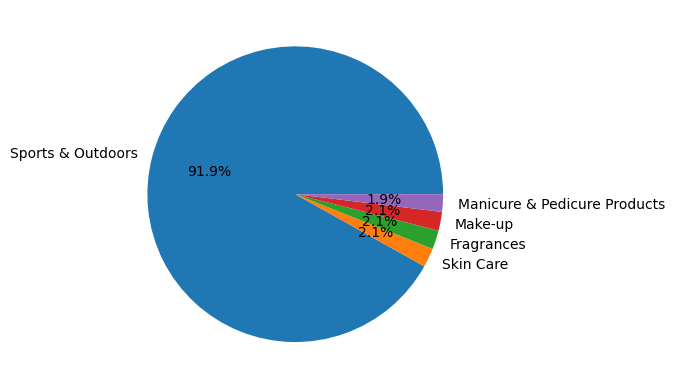

In [36]:
plt.pie(top_category, labels=top_category.index, autopct ='%1.1f%%')
plt.show()

# Piechar
Podemos obserbar que, en porcentage, sports y outdors ocupa un **91,91%** del grafico del top 5 categorias

### Parte 2

# 2.1

In [37]:
media = df['price'].mean()
mediana = df['price'].median()
moda = df['price'].mode()[0]



In [38]:
print(f"Media: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Moda: {moda:.2f}")

Media: 94.26
Mediana: 19.90
Moda: 9.99


La media es mucho mayor que la mediana, esto nos indica que la distribuicon esta sesgada a la derecha. Esto indica que unos pocos productos hacen subir la media

# 2.2

In [ ]:
rango = df['price'].max() - df['price'].min()
varianza =df['price'].var()
desviacion =df['price'].std()

In [55]:
print(f"Rango: {rango}")
print(f"Varianza: {varianza:.2f}")
print(f"Desviacion estandar: {desviacion:.2f}")

Rango: 100000.0
Varianza: 130048.57
Desviacion estandar: 360.62


Los precios muestran una variación muy grande. La desviación estándar de **360.62** es significativamente mayor que la media **94.26**, lo que sugiere que los datos están muy dispersos y no centrados. Además, el rango masivo y la gran diferencia entre media y mediana indican la presencia de valores atípicos muy fuertes (productos muy caros) que sesgan la distribución.

# Histograma con todos los valores


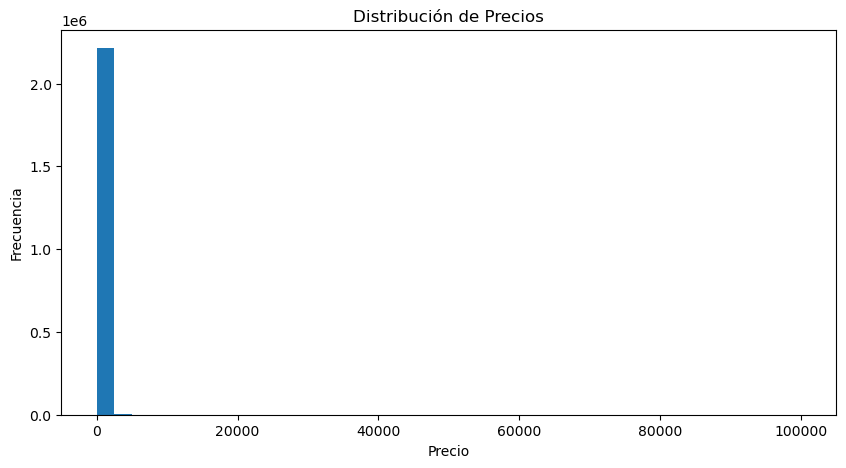

In [66]:
plt.figure(figsize=(10, 5))
plt.hist(df['price'], bins=40)
plt.title('Distribución de Precios')
plt.xlabel('Precio')
plt.ylabel('Frecuencia')
plt.show()

# Histograma con valores menores de 250


<Axes: ylabel='Frequency'>

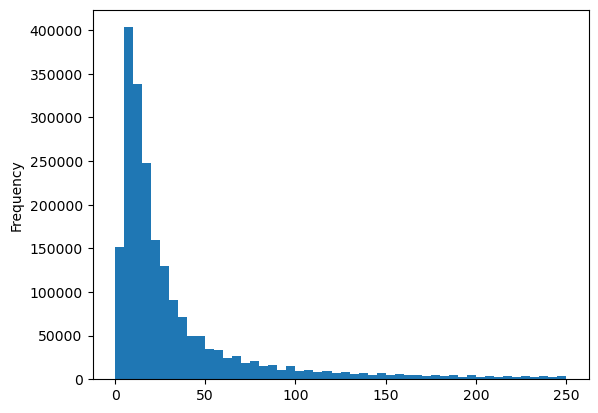

In [73]:
df[df['price'] < 250]['price'].plot(kind='hist', bins=50)

Podemos observar una distribucion asimetrica hacia la derecha, poniendo como limite de precio ***250***. Lo que indica que hay productos significativamente mas altos que el promedio

# BOX PLOT


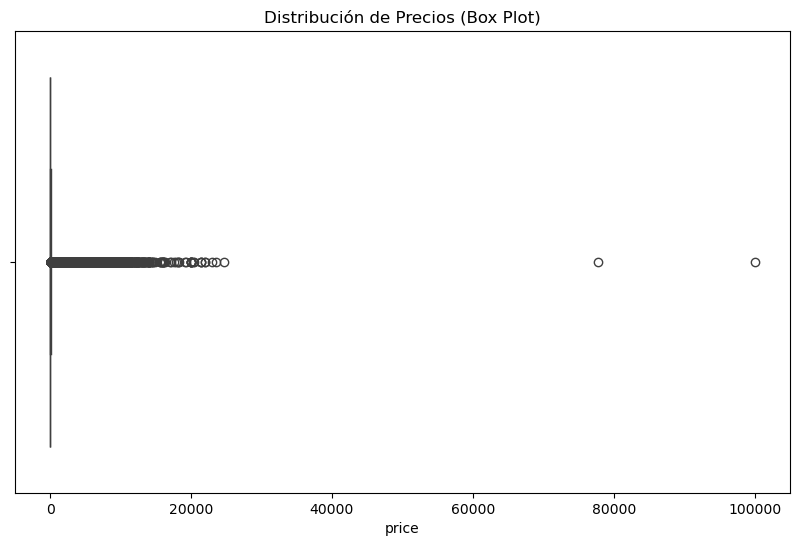

In [70]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['price'])
plt.title('Distribución de Precios (Box Plot)')
plt.show()

Como muestra el boxplot, hay outliers hacia la derecha, con valores entre . La inmensa mayoria de valor de los productos se condensa en la izquierda

### Parte 3

# 3.1

In [77]:
media_stars = df['stars'].mean()
mediana_stars = df['stars'].median()
moda_stars = df['stars'].mode()[0]

In [78]:
print(f"Media: {media_stars:.2f}")
print(f"Mediana: {mediana_stars:.2f}")
print(f"Moda: {moda_stars:.2f}")

Media: 2.03
Mediana: 0.00
Moda: 0.00


In [79]:
(df['stars'] == 0).sum()

np.int64(1174420)

In [80]:
(df['stars'] == 0).mean() * 100

np.float64(52.83654153293544)

Podemos observar que los valores de la mediana y la moda son 0. Con una cantidad total  de ***1174420*** productos con 0 'stars' y con un porcentage del ***52.84%***, esto indica que mas de la mitad de los productos no han sido calificados lo que hace bajar la media a un valor de ***2.03***

# 3.2

In [86]:
varianza_stars =df['stars'].var()
desviacion_stars =df['stars'].std()
rango_inter = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

In [85]:
print(f"Varianza: {varianza_stars:.2f}")
print(f"Desviacion estandar: {desviacion_stars:.2f}")
print(f"Rango interquartilico: {rango_inter:.2f}")

Varianza: 4.78
Desviacion estandar: 2.19
Rango interquartilico: 4.40


No hay consistencia. Hay una variacion muy gran. Los clientes se dividen entre no poner calificar los producto o entre ***4-5 stars***

# 3.3

In [87]:
print(f"Skewness: {df['stars'].skew():.2f}")
print(f"Kurtosis: {df['stars'].kurt():.2f}")

Skewness: 0.19
Kurtosis: -1.90


La simetria indica  que los datos estan a la izquierda pero manteniendo un equlibrio entre los extremos
En el caso de la Kurtosis, es negativa ***-0.19***. Esto significa que la curva esta es negatvia en el centro y que hay pocos datos entre los valores medios

# 3.4

<Axes: >

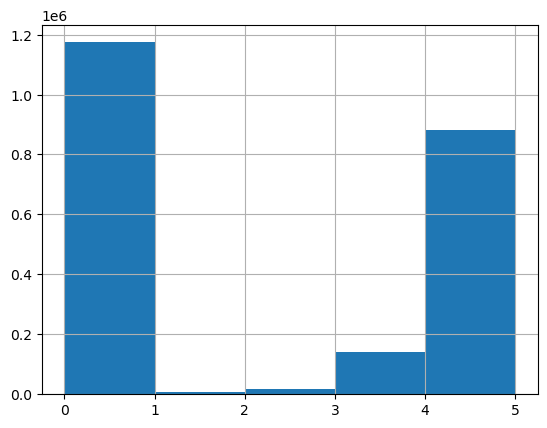

In [88]:
df['stars'].hist(bins=5)

Podemos observar claramente dos tendencias. La puntuación más común es 0 (el 52.84% de los productos). Sin embargo, entre los productos que sí han sido valorados, la puntuación más frecuente es 5 estrellas. Esto confirma que la distribución está polarizada: o el producto no tiene votos, o los clientes tienden a valorarlo muy positivamente.

Conclusión General del Análisis 
1. Categorías: Hemos visto que Sports & Outdoors es, con diferencia, la categoría dominante en este dataset.

2. Precios: La distribución de precios es muy desigual. La gran mayoría de productos son baratos (por debajo de la media de ***94***), pero existen unos pocos artículos con precios altísimos que distorsionan el promedio. No hay un "precio estándar", depende mucho del producto.

3. Valoraciones: Más de la mitad de los productos ***52%*** no tienen ninguna valoración (0 estrellas). De los que sí tienen votos, la mayoría son excelentes (4-5 estrellas). Básicamente: o el producto es ignorado, o es amado.